# ***SHE-GUARD — Motion & Activity Recognition***


**Version:** v1.0 — Initial Dataset Exploration

**Dataset:** UCI Human Activity Recognition Using Smartphones

**Objective:** Build and evaluate a machine learning prototype to classify human activities using accelerometer and gyroscope data.

**Workflow:** Dataset → Data Exploration → Preprocessing → Baseline Model → Evaluation → Model Saving

**Important limitation:** Activity recognition does not establish whether a person is in danger. Manual SOS remains independent of ML predictions.

In [ ]:
from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving human+activity+recognition+using+smartphones.zip to human+activity+recognition+using+smartphones.zip

Uploaded files:
human+activity+recognition+using+smartphones.zip


In [ ]:
import zipfile
import os

zip_path = "/content/human+activity+recognition+using+smartphones.zip"

print("ZIP exists:", os.path.exists(zip_path))

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    files_list = zip_ref.namelist()

    print("\nTotal files inside ZIP:", len(files_list))
    print("\nFirst 30 files:")

    for filename in files_list[:30]:
        print(filename)

ZIP exists: True

Total files inside ZIP: 2

First 30 files:
UCI HAR Dataset.names
UCI HAR Dataset.zip


In [ ]:
import zipfile
import os

outer_zip = "/content/human+activity+recognition+using+smartphones.zip"
extract_path = "/content/she_guard_motion_data"

# Extract the downloaded ZIP
with zipfile.ZipFile(outer_zip, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Locate the inner ZIP
inner_zip = os.path.join(
    extract_path,
    "UCI HAR Dataset.zip"
)

print("Inner ZIP exists:", os.path.exists(inner_zip))
print("Inner ZIP path:", inner_zip)

Inner ZIP exists: True
Inner ZIP path: /content/she_guard_motion_data/UCI HAR Dataset.zip


In [ ]:
import zipfile
import os

inner_zip = "/content/she_guard_motion_data/UCI HAR Dataset.zip"
dataset_path = "/content/she_guard_motion_data/extracted"

os.makedirs(dataset_path, exist_ok=True)

with zipfile.ZipFile(inner_zip, "r") as zip_ref:
    zip_ref.extractall(dataset_path)

print("Extraction successful!")
print("\nMain folders and files:")

for item in os.listdir(dataset_path):
    print(item)

Extraction successful!

Main folders and files:
UCI HAR Dataset
__MACOSX


In [ ]:
import os

dataset_root = "/content/she_guard_motion_data/extracted/UCI HAR Dataset"

print("Dataset folder exists:", os.path.exists(dataset_root))
print("\nMain contents:")

for item in sorted(os.listdir(dataset_root)):
    full_path = os.path.join(dataset_root, item)

    if os.path.isdir(full_path):
        print(f"[FOLDER] {item}")
    else:
        print(f"[FILE]   {item}")

Dataset folder exists: True

Main contents:
[FILE]   .DS_Store
[FILE]   README.txt
[FILE]   activity_labels.txt
[FILE]   features.txt
[FILE]   features_info.txt
[FOLDER] test
[FOLDER] train


In [ ]:
import os

dataset_root = "/content/she_guard_motion_data/extracted/UCI HAR Dataset"

for split in ["train", "test"]:
    split_path = os.path.join(dataset_root, split)

    print(f"\n{'=' * 15} {split.upper()} {'=' * 15}")

    for folder in ["Inertial Signals"]:
        path = os.path.join(split_path, folder)
        print(f"{folder} exists:", os.path.isdir(path))

    for filename in [
        "X_" + split + ".txt",
        "y_" + split + ".txt",
        "subject_" + split + ".txt"
    ]:
        path = os.path.join(split_path, filename)
        print(f"{filename}: exists =", os.path.isfile(path))

print("\nActivity labels:")
with open(os.path.join(dataset_root, "activity_labels.txt")) as f:
    print(f.read())

print("Feature count:", sum(
    1 for _ in open(os.path.join(dataset_root, "features.txt"))
))


=============== TRAIN ===============
Inertial Signals exists: True
X_train.txt: exists = True
y_train.txt: exists = True
subject_train.txt: exists = True

=============== TEST ===============
Inertial Signals exists: True
X_test.txt: exists = True
y_test.txt: exists = True
subject_test.txt: exists = True

Activity labels:
1 WALKING
2 WALKING_UPSTAIRS
3 WALKING_DOWNSTAIRS
4 SITTING
5 STANDING
6 LAYING

Feature count: 561


In [ ]:
import os
import numpy as np

dataset_root = "/content/she_guard_motion_data/extracted/UCI HAR Dataset"

# 1. Check the number of samples
for split in ["train", "test"]:
    split_path = os.path.join(dataset_root, split)

    X = np.loadtxt(os.path.join(split_path, f"X_{split}.txt"))
    y = np.loadtxt(os.path.join(split_path, f"y_{split}.txt"), dtype=int)
    subjects = np.loadtxt(
        os.path.join(split_path, f"subject_{split}.txt"),
        dtype=int
    )

    print(f"\n{split.upper()} DATA")
    print("Feature matrix shape:", X.shape)
    print("Labels shape:", y.shape)
    print("Unique subjects:", len(np.unique(subjects)))

# 2. Inspect raw inertial signal filenames
signal_path = os.path.join(
    dataset_root, "train", "Inertial Signals"
)

print("\nRaw sensor signal files:")
for filename in sorted(os.listdir(signal_path)):
    print(filename)


TRAIN DATA
Feature matrix shape: (7352, 561)
Labels shape: (7352,)
Unique subjects: 21

TEST DATA
Feature matrix shape: (2947, 561)
Labels shape: (2947,)
Unique subjects: 9

Raw sensor signal files:
body_acc_x_train.txt
body_acc_y_train.txt
body_acc_z_train.txt
body_gyro_x_train.txt
body_gyro_y_train.txt
body_gyro_z_train.txt
total_acc_x_train.txt
total_acc_y_train.txt
total_acc_z_train.txt


In [ ]:
import os
import numpy as np
from collections import Counter

dataset_root = "/content/she_guard_motion_data/extracted/UCI HAR Dataset"

activity_names = {
    1: "WALKING",
    2: "WALKING_UPSTAIRS",
    3: "WALKING_DOWNSTAIRS",
    4: "SITTING",
    5: "STANDING",
    6: "LAYING"
}

for split in ["train", "test"]:
    y_path = os.path.join(
        dataset_root, split, f"y_{split}.txt"
    )

    y = np.loadtxt(y_path, dtype=int)
    counts = Counter(y)

    print(f"\n{'=' * 10} {split.upper()} ACTIVITY DISTRIBUTION {'=' * 10}")

    for activity_id, name in activity_names.items():
        count = counts.get(activity_id, 0)
        percentage = count / len(y) * 100

        print(f"{name:20s} {count:4d} samples ({percentage:.2f}%)")


========== TRAIN ACTIVITY DISTRIBUTION ==========
WALKING              1226 samples (16.68%)
WALKING_UPSTAIRS     1073 samples (14.59%)
WALKING_DOWNSTAIRS    986 samples (13.41%)
SITTING              1286 samples (17.49%)
STANDING             1374 samples (18.69%)
LAYING               1407 samples (19.14%)

========== TEST ACTIVITY DISTRIBUTION ==========
WALKING               496 samples (16.83%)
WALKING_UPSTAIRS      471 samples (15.98%)
WALKING_DOWNSTAIRS    420 samples (14.25%)
SITTING               491 samples (16.66%)
STANDING              532 samples (18.05%)
LAYING                537 samples (18.22%)


In [ ]:
import os
import pandas as pd
import numpy as np

dataset_root = "/content/she_guard_motion_data/extracted/UCI HAR Dataset"

# Read feature names
features = pd.read_csv(
    os.path.join(dataset_root, "features.txt"),
    sep=r"\s+",
    header=None,
    names=["index", "feature_name"]
)

# Read a small sample only
X_train_sample = pd.read_csv(
    os.path.join(dataset_root, "train", "X_train.txt"),
    sep=r"\s+",
    header=None,
    nrows=5
)

X_train_sample.columns = features["feature_name"].tolist()

print("Number of feature names:", len(features))
print("\nFirst 20 feature names:")
print(features["feature_name"].head(20).to_list())

print("\nFirst 5 rows, first 8 features:")
print(X_train_sample.iloc[:, :8].round(3))

print("\nMissing values in this sample:",
      X_train_sample.isna().sum().sum())

Number of feature names: 561

First 20 feature names:
['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z', 'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z', 'tBodyAcc-mad()-X', 'tBodyAcc-mad()-Y', 'tBodyAcc-mad()-Z', 'tBodyAcc-max()-X', 'tBodyAcc-max()-Y', 'tBodyAcc-max()-Z', 'tBodyAcc-min()-X', 'tBodyAcc-min()-Y', 'tBodyAcc-min()-Z', 'tBodyAcc-sma()', 'tBodyAcc-energy()-X', 'tBodyAcc-energy()-Y', 'tBodyAcc-energy()-Z', 'tBodyAcc-iqr()-X']

First 5 rows, first 8 features:
   tBodyAcc-mean()-X  tBodyAcc-mean()-Y  tBodyAcc-mean()-Z  tBodyAcc-std()-X  \
0              0.289             -0.020             -0.133            -0.995   
1              0.278             -0.016             -0.124            -0.998   
2              0.280             -0.019             -0.113            -0.995   
3              0.279             -0.026             -0.123            -0.996   
4              0.277             -0.017             -0.115            -0.998   

   tBodyAcc-std()-Y  

In [ ]:
import os
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

dataset_root = "/content/she_guard_motion_data/extracted/UCI HAR Dataset"

# Load training data
X_train = np.loadtxt(
    os.path.join(dataset_root, "train", "X_train.txt")
)
y_train = np.loadtxt(
    os.path.join(dataset_root, "train", "y_train.txt"),
    dtype=int
)

# Load held-out test data
X_test = np.loadtxt(
    os.path.join(dataset_root, "test", "X_test.txt")
)
y_test = np.loadtxt(
    os.path.join(dataset_root, "test", "y_test.txt"),
    dtype=int
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

# Train baseline model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("\nBaseline training complete!")

# Initial held-out test accuracy
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Held-out test accuracy: {accuracy:.4f}")
print(f"Held-out test accuracy: {accuracy * 100:.2f}%")

Training shape: (7352, 561)
Testing shape: (2947, 561)

Baseline training complete!
Held-out test accuracy: 0.9257
Held-out test accuracy: 92.57%


CLASSIFICATION REPORT

                    precision    recall  f1-score   support

           WALKING     0.8887    0.9657    0.9256       496
  WALKING_UPSTAIRS     0.8845    0.8938    0.8891       471
WALKING_DOWNSTAIRS     0.9704    0.8595    0.9116       420
           SITTING     0.9112    0.8982    0.9046       491
          STANDING     0.9072    0.9192    0.9132       532
            LAYING     1.0000    1.0000    1.0000       537

          accuracy                         0.9257      2947
         macro avg     0.9270    0.9227    0.9240      2947
      weighted avg     0.9270    0.9257    0.9256      2947



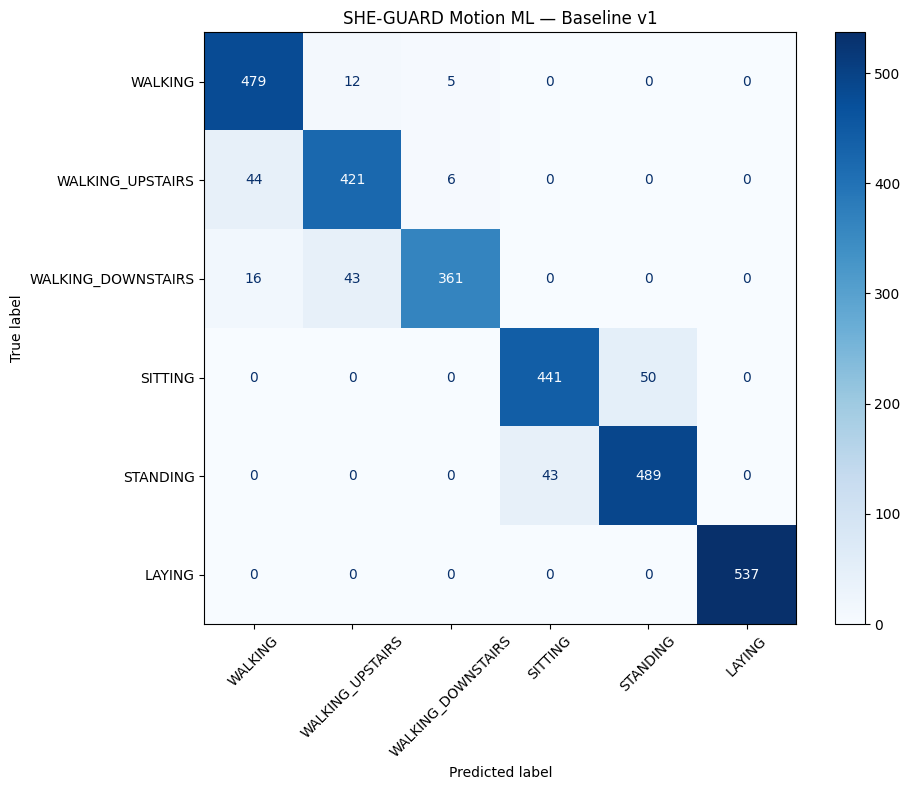

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

activity_names = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

labels = [1, 2, 3, 4, 5, 6]

# Detailed metrics for each activity
print("CLASSIFICATION REPORT\n")

print(classification_report(
    y_test,
    y_pred,
    labels=labels,
    target_names=activity_names,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=labels)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=activity_names
)

fig, ax = plt.subplots(figsize=(10, 8))
display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)
plt.title("SHE-GUARD Motion ML — Baseline v1")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (
    precision_recall_fscore_support,
    confusion_matrix
)
import numpy as np

labels = [1, 2, 3, 4, 5, 6]

names = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

precision, recall, f1, support = precision_recall_fscore_support(
    y_test,
    y_pred,
    labels=labels,
    zero_division=0
)

cm = confusion_matrix(y_test, y_pred, labels=labels)

print("ACTIVITY-WISE ERROR ANALYSIS\n")

for i, name in enumerate(names):
    false_positives = cm[:, i].sum() - cm[i, i]
    false_negatives = cm[i, :].sum() - cm[i, i]

    print(f"{name}")
    print(f"  Recall:          {recall[i]:.3f}")
    print(f"  False positives: {false_positives}")
    print(f"  False negatives: {false_negatives}")
    print()

ACTIVITY-WISE ERROR ANALYSIS

WALKING
  Recall:          0.966
  False positives: 60
  False negatives: 17

WALKING_UPSTAIRS
  Recall:          0.894
  False positives: 55
  False negatives: 50

WALKING_DOWNSTAIRS
  Recall:          0.860
  False positives: 11
  False negatives: 59

SITTING
  Recall:          0.898
  False positives: 43
  False negatives: 50

STANDING
  Recall:          0.919
  False positives: 50
  False negatives: 43

LAYING
  Recall:          1.000
  False positives: 0
  False negatives: 0



PAMAP2 Dataset — Wrist Sensor Analysis

Dataset: PAMAP2 Physical Activity Monitoring

Sensor placement: Dominant wrist
Sampling frequency: 100 Hz

Initial task: Running vs other verified activities

Input: Wrist accelerometer and gyroscope
Labels: Original activityID

Limitation: Running does not establish distress or danger.

In [ ]:
from google.colab import files

uploaded = files.upload()

print("\nUploaded file names:")
for filename in uploaded.keys():
    print(filename)

Saving subject109.csv.zip to subject109.csv.zip

Uploaded file names:
subject109.csv.zip


In [ ]:
import zipfile
import os

zip_path = "/content/subject109.csv.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files inside ZIP:")
    for name in z.namelist():
        print(name)

Files inside ZIP:
subject109.csv


In [ ]:
import zipfile
import pandas as pd

zip_path = "/content/subject109.csv.zip"

# Read CSV directly from ZIP without extracting it
with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("subject109.csv") as f:
        df_sample = pd.read_csv(f, nrows=5)

print("Column count:", len(df_sample.columns))
print("\nColumn names:")
for i, col in enumerate(df_sample.columns):
    print(i, ":", col)

print("\nFirst 5 rows:")
display(df_sample.head())

print("\nData types:")
print(df_sample.dtypes)

Column count: 54

Column names:
0 : timestamps
1 : activityID
2 : heart_rate
3 : IMU_hand_temperature
4 : IMU_hand_acceleration_16g_1
5 : IMU_hand_acceleration_16g_2
6 : IMU_hand_acceleration_16g_3
7 : IMU_hand_acceleration_6g_1
8 : IMU_hand_acceleration_6g_2
9 : IMU_hand_acceleration_6g_3
10 : IMU_hand_gyroscope_1
11 : IMU_hand_gyroscope_2
12 : IMU_hand_gyroscope_3
13 : IMU_hand_magnetometer_1
14 : IMU_hand_magnetometer_2
15 : IMU_hand_magnetometer_3
16 : IMU_hand_orientation_1
17 : IMU_hand_orientation_2
18 : IMU_hand_orientation_3
19 : IMU_hand_orientation_4
20 : IMU_chest_temperature
21 : IMU_chest_acceleration_16g_1
22 : IMU_chest_acceleration_16g_2
23 : IMU_chest_acceleration_16g_3
24 : IMU_chest_acceleration_6g_1
25 : IMU_chest_acceleration_6g_2
26 : IMU_chest_acceleration_6g_3
27 : IMU_chest_gyroscope_1
28 : IMU_chest_gyroscope_2
29 : IMU_chest_gyroscope_3
30 : IMU_chest_magnetometer_1
31 : IMU_chest_magnetometer_2
32 : IMU_chest_magnetometer_3
33 : IMU_chest_orientation_1
34 :

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [ ]:
from IPython.display import display as show_table
import zipfile
import pandas as pd

zip_path = "/content/subject109.csv.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("subject109.csv") as f:
        df_sample = pd.read_csv(f, nrows=5)

print("Column count:", len(df_sample.columns))

print("\nColumn names:")
for i, col in enumerate(df_sample.columns):
    print(i, ":", col)

print("\nFirst 5 rows:")
show_table(df_sample.head())

print("\nData types:")
print(df_sample.dtypes)

Column count: 54

Column names:
0 : timestamps
1 : activityID
2 : heart_rate
3 : IMU_hand_temperature
4 : IMU_hand_acceleration_16g_1
5 : IMU_hand_acceleration_16g_2
6 : IMU_hand_acceleration_16g_3
7 : IMU_hand_acceleration_6g_1
8 : IMU_hand_acceleration_6g_2
9 : IMU_hand_acceleration_6g_3
10 : IMU_hand_gyroscope_1
11 : IMU_hand_gyroscope_2
12 : IMU_hand_gyroscope_3
13 : IMU_hand_magnetometer_1
14 : IMU_hand_magnetometer_2
15 : IMU_hand_magnetometer_3
16 : IMU_hand_orientation_1
17 : IMU_hand_orientation_2
18 : IMU_hand_orientation_3
19 : IMU_hand_orientation_4
20 : IMU_chest_temperature
21 : IMU_chest_acceleration_16g_1
22 : IMU_chest_acceleration_16g_2
23 : IMU_chest_acceleration_16g_3
24 : IMU_chest_acceleration_6g_1
25 : IMU_chest_acceleration_6g_2
26 : IMU_chest_acceleration_6g_3
27 : IMU_chest_gyroscope_1
28 : IMU_chest_gyroscope_2
29 : IMU_chest_gyroscope_3
30 : IMU_chest_magnetometer_1
31 : IMU_chest_magnetometer_2
32 : IMU_chest_magnetometer_3
33 : IMU_chest_orientation_1
34 :

,timestamps,activityID,heart_rate,IMU_hand_temperature,IMU_hand_acceleration_16g_1,IMU_hand_acceleration_16g_2,IMU_hand_acceleration_16g_3,IMU_hand_acceleration_6g_1,IMU_hand_acceleration_6g_2,IMU_hand_acceleration_6g_3,...,IMU_ankle_gyroscope_1,IMU_ankle_gyroscope_2,IMU_ankle_gyroscope_3,IMU_ankle_magnetometer_1,IMU_ankle_magnetometer_2,IMU_ankle_magnetometer_3,IMU_ankle_orientation_1,IMU_ankle_orientation_2,IMU_ankle_orientation_3,IMU_ankle_orientation_4
0,15.47,0,141.0,24.75,-9.98278,2.61759,2.46038,-10.23410,2.69055,2.45977,...,0.714237,-0.235885,-0.341782,-44.2263,-10.2857,7.36341,0.466904,-0.486197,0.608846,-0.418234
1,15.48,0,NaN,24.75,-9.75577,2.46441,2.50279,-9.96280,2.56789,2.58057,...,0.238571,-0.279597,-0.536439,-44.3354,-10.7931,8.07278,0.466590,-0.488971,0.607694,-0.417024
2,15.49,0,NaN,24.75,-10.32720,2.43953,3.45650,-9.96105,2.44737,2.91305,...,-0.122434,-0.307176,-0.737734,-44.4643,-10.6575,8.21400,0.466964,-0.492189,0.607102,-0.413669
3,15.50,0,NaN,24.75,-10.99920,2.29537,3.71633,-10.53000,2.45190,3.36664,...,-0.347597,-0.349365,-0.938808,-44.2026,-11.1868,7.79004,0.468730,-0.494896,0.606311,-0.409581
4,15.51,0,NaN,24.75,-10.88630,1.83990,3.79653,-11.07110,2.25982,3.73003,...,-0.469862,-0.457702,-1.059880,-43.4225,-11.8694,7.79357,0.469978,-0.497652,0.605975,-0.405287



Data types:
timestamps                      float64
activityID                        int64
heart_rate                      float64
IMU_hand_temperature            float64
IMU_hand_acceleration_16g_1     float64
IMU_hand_acceleration_16g_2     float64
IMU_hand_acceleration_16g_3     float64
IMU_hand_acceleration_6g_1      float64
IMU_hand_acceleration_6g_2      float64
IMU_hand_acceleration_6g_3      float64
IMU_hand_gyroscope_1            float64
IMU_hand_gyroscope_2            float64
IMU_hand_gyroscope_3            float64
IMU_hand_magnetometer_1         float64
IMU_hand_magnetometer_2         float64
IMU_hand_magnetometer_3         float64
IMU_hand_orientation_1          float64
IMU_hand_orientation_2          float64
IMU_hand_orientation_3          float64
IMU_hand_orientation_4          float64
IMU_chest_temperature           float64
IMU_chest_acceleration_16g_1    float64
IMU_chest_acceleration_16g_2    float64
IMU_chest_acceleration_16g_3    float64
IMU_chest_acceleration_6g_1

In [ ]:
import zipfile
import pandas as pd

zip_path = "/content/subject109.csv.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("subject109.csv") as f:
        df = pd.read_csv(f, nrows=100)

print("All activity-related columns:")
print([c for c in df.columns if "activity" in c.lower()])

print("\nWrist sensor columns:")
print([c for c in df.columns if "wrist" in c.lower()])

print("\nFirst 5 activity labels:")
print(df["activityID"].head().tolist())

print("\nActivity label counts in these 100 rows:")
print(df["activityID"].value_counts(dropna=False).sort_index())

print("\nFirst 5 rows of selected columns:")
selected = [
    c for c in df.columns
    if c == "activityID"
    or "wrist_acceleration_16g" in c.lower()
    or "wrist_gyroscope" in c.lower()
]
print(selected)
print(df[selected].head().to_string(index=False))

All activity-related columns:
['activityID']

Wrist sensor columns:
[]

First 5 activity labels:
[0, 0, 0, 0, 0]

Activity label counts in these 100 rows:
activityID
0    100
Name: count, dtype: int64

First 5 rows of selected columns:
['activityID']
 activityID
          0
          0
          0
          0
          0


In [ ]:
import zipfile
import pandas as pd

zip_path = "/content/subject109.csv.zip"

# Read the full CSV to inspect all activities and columns
with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("subject109.csv") as f:
        df = pd.read_csv(f)

print("Dataset shape:", df.shape)

print("\nFirst 20 column names:")
print(df.columns.tolist()[:20])

print("\nColumns containing 'IMU':")
print([c for c in df.columns if "imu" in c.lower()])

print("\nActivity distribution across the full file:")
print(df["activityID"].value_counts(dropna=False).sort_index())

print("\nMissing activity labels:", df["activityID"].isna().sum())

Dataset shape: (8477, 54)

First 20 column names:
['timestamps', 'activityID', 'heart_rate', 'IMU_hand_temperature', 'IMU_hand_acceleration_16g_1', 'IMU_hand_acceleration_16g_2', 'IMU_hand_acceleration_16g_3', 'IMU_hand_acceleration_6g_1', 'IMU_hand_acceleration_6g_2', 'IMU_hand_acceleration_6g_3', 'IMU_hand_gyroscope_1', 'IMU_hand_gyroscope_2', 'IMU_hand_gyroscope_3', 'IMU_hand_magnetometer_1', 'IMU_hand_magnetometer_2', 'IMU_hand_magnetometer_3', 'IMU_hand_orientation_1', 'IMU_hand_orientation_2', 'IMU_hand_orientation_3', 'IMU_hand_orientation_4']

Columns containing 'IMU':
['IMU_hand_temperature', 'IMU_hand_acceleration_16g_1', 'IMU_hand_acceleration_16g_2', 'IMU_hand_acceleration_16g_3', 'IMU_hand_acceleration_6g_1', 'IMU_hand_acceleration_6g_2', 'IMU_hand_acceleration_6g_3', 'IMU_hand_gyroscope_1', 'IMU_hand_gyroscope_2', 'IMU_hand_gyroscope_3', 'IMU_hand_magnetometer_1', 'IMU_hand_magnetometer_2', 'IMU_hand_magnetometer_3', 'IMU_hand_orientation_1', 'IMU_hand_orientation_2', 'IM

In [ ]:
import zipfile
import pandas as pd

zip_path = "/content/subject109.csv.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("subject109.csv") as f:
        df = pd.read_csv(f, usecols=["activityID"])

print("Available activity IDs:")
print(sorted(df["activityID"].unique()))

print("\nRunning samples (ID 5):", (df["activityID"] == 5).sum())
print("Walking samples (ID 4):", (df["activityID"] == 4).sum())
print("Other/transient samples (ID 0):", (df["activityID"] == 0).sum())

Available activity IDs:
[np.int64(0), np.int64(24)]

Running samples (ID 5): 0
Walking samples (ID 4): 0
Other/transient samples (ID 0): 2086


In [ ]:
from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving subject101.csv.zip to subject101.csv.zip

Uploaded files:
subject101.csv.zip


In [ ]:
import os

print("Current files in /content:\n")

for name in os.listdir("/content"):
    print(name)

Current files in /content:

.config
sample_data


In [ ]:
from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving subject101.csv.zip to subject101.csv.zip

Uploaded files:
subject101.csv.zip


In [ ]:
import os
import zipfile
import pandas as pd

zip_path = "/content/subject101.csv.zip"

# Verify file exists
print("ZIP exists:", os.path.exists(zip_path))

# Inspect ZIP and activity labels
with zipfile.ZipFile(zip_path, "r") as z:
    print("Files inside ZIP:", z.namelist())

    with z.open("subject101.csv") as f:
        df = pd.read_csv(f, usecols=["activityID"])

print("\nDataset shape:", df.shape)

print("\nActivity distribution:")
print(df["activityID"].value_counts().sort_index())

print("\nRunning samples (ID 5):", (df["activityID"] == 5).sum())
print("Walking samples (ID 4):", (df["activityID"] == 4).sum())
print("Other/transient samples (ID 0):", (df["activityID"] == 0).sum())

ZIP exists: True
Files inside ZIP: ['subject101.csv']

Dataset shape: (376417, 1)

Activity distribution:
activityID
0     126460
1      27187
2      23480
3      21717
4      22253
5      21265
6      23575
7      20265
12     15890
13     14899
16     22941
17     23573
24     12912
Name: count, dtype: int64

Running samples (ID 5): 21265
Walking samples (ID 4): 22253
Other/transient samples (ID 0): 126460


In [ ]:
import zipfile
import pandas as pd

zip_path = "/content/subject101.csv.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("subject101.csv") as f:
        df = pd.read_csv(f)

wrist_cols = [
    "IMU_hand_acceleration_16g_1",
    "IMU_hand_acceleration_16g_2",
    "IMU_hand_acceleration_16g_3",
    "IMU_hand_gyroscope_1",
    "IMU_hand_gyroscope_2",
    "IMU_hand_gyroscope_3"
]

print("Dataset shape:", df.shape)

print("\nSelected wrist columns available:")
for col in wrist_cols:
    print(col, "->", col in df.columns)

print("\nMissing values in wrist columns:")
print(df[wrist_cols].isna().sum())

print("\nFirst 5 wrist readings:")
print(df[wrist_cols].head().round(3))

Dataset shape: (376417, 54)

Selected wrist columns available:
IMU_hand_acceleration_16g_1 -> True
IMU_hand_acceleration_16g_2 -> True
IMU_hand_acceleration_16g_3 -> True
IMU_hand_gyroscope_1 -> True
IMU_hand_gyroscope_2 -> True
IMU_hand_gyroscope_3 -> True

Missing values in wrist columns:
IMU_hand_acceleration_16g_1    1454
IMU_hand_acceleration_16g_2    1454
IMU_hand_acceleration_16g_3    1454
IMU_hand_gyroscope_1           1454
IMU_hand_gyroscope_2           1454
IMU_hand_gyroscope_3           1454
dtype: int64

First 5 wrist readings:
   IMU_hand_acceleration_16g_1  IMU_hand_acceleration_16g_2  \
0                        2.372                        8.601   
1                        2.188                        8.566   
2                        2.374                        8.601   
3                        2.075                        8.529   
4                        2.229                        8.831   

   IMU_hand_acceleration_16g_3  IMU_hand_gyroscope_1  IMU_hand_gyroscope_2 

In [ ]:
import zipfile
import pandas as pd

zip_path = "/content/subject101.csv.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("subject101.csv") as f:
        df = pd.read_csv(f)

wrist_cols = [
    "IMU_hand_acceleration_16g_1",
    "IMU_hand_acceleration_16g_2",
    "IMU_hand_acceleration_16g_3",
    "IMU_hand_gyroscope_1",
    "IMU_hand_gyroscope_2",
    "IMU_hand_gyroscope_3"
]

# Check whether missing values occur on the same rows
missing_per_row = df[wrist_cols].isna().sum(axis=1)

print("Rows with no missing wrist readings:",
      (missing_per_row == 0).sum())

print("Rows with any missing wrist reading:",
      (missing_per_row > 0).sum())

print("\nMissing-value pattern:")
print(missing_per_row.value_counts().sort_index())

print("\nActivity counts:")
print(df["activityID"].value_counts().sort_index())

Rows with no missing wrist readings: 374963
Rows with any missing wrist reading: 1454

Missing-value pattern:
0    374963
6      1454
Name: count, dtype: int64

Activity counts:
activityID
0     126460
1      27187
2      23480
3      21717
4      22253
5      21265
6      23575
7      20265
12     15890
13     14899
16     22941
17     23573
24     12912
Name: count, dtype: int64


In [ ]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded:
    print(filename)

Saving subject102.csv.zip to subject102.csv.zip
Uploaded files:
subject102.csv.zip


In [ ]:
import zipfile
import pandas as pd
import os

zip_path = "/content/subject102.csv.zip"

print("ZIP exists:", os.path.exists(zip_path))

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files inside ZIP:", z.namelist())

    with z.open("subject102.csv") as f:
        df = pd.read_csv(f, usecols=["activityID"])

print("\nDataset shape:", df.shape)
print("\nActivity distribution:")
print(df["activityID"].value_counts().sort_index())

print("\nRunning samples (ID 5):",
      (df["activityID"] == 5).sum())

print("Walking samples (ID 4):",
      (df["activityID"] == 4).sum())

ZIP exists: True
Files inside ZIP: ['subject102.csv']

Dataset shape: (447000, 1)

Activity distribution:
activityID
0     183651
1      23430
2      22345
3      25576
4      32533
5       9238
6      25108
7      29739
12     17342
13     15213
16     20683
17     28880
24     13262
Name: count, dtype: int64

Running samples (ID 5): 9238
Walking samples (ID 4): 32533


In [ ]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded:
    print(filename)

Saving subject103.csv.zip to subject103.csv.zip
Uploaded files:
subject103.csv.zip


In [ ]:
import zipfile
import pandas as pd
import os

zip_path = "/content/subject103.csv.zip"

print("ZIP exists:", os.path.exists(zip_path))

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files inside ZIP:", z.namelist())

    with z.open("subject103.csv") as f:
        df = pd.read_csv(f, usecols=["activityID"])

print("\nDataset shape:", df.shape)

print("\nActivity distribution:")
print(df["activityID"].value_counts().sort_index())

print("\nRunning samples (ID 5):",
      (df["activityID"] == 5).sum())

print("Walking samples (ID 4):",
      (df["activityID"] == 4).sum())

ZIP exists: True
Files inside ZIP: ['subject103.csv']

Dataset shape: (252833, 1)

Activity distribution:
activityID
0     78495
1     22044
2     28761
3     20533
4     29036
12    10389
13    15275
16    20325
17    27975
Name: count, dtype: int64

Running samples (ID 5): 0
Walking samples (ID 4): 29036


In [ ]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded:
    print(filename)

Saving subject104.csv.zip to subject104.csv.zip
Uploaded files:
subject104.csv.zip


In [ ]:
import zipfile
import pandas as pd
import os

zip_path = "/content/subject104.csv.zip"

print("ZIP exists:", os.path.exists(zip_path))

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files inside ZIP:", z.namelist())

    with z.open("subject104.csv") as f:
        df = pd.read_csv(f, usecols=["activityID"])

print("\nDataset shape:", df.shape)

print("\nActivity distribution:")
print(df["activityID"].value_counts().sort_index())

print("\nRunning samples (ID 5):",
      (df["activityID"] == 5).sum())

print("Walking samples (ID 4):",
      (df["activityID"] == 4).sum())

ZIP exists: True
Files inside ZIP: ['subject104.csv']

Dataset shape: (329576, 1)

Activity distribution:
activityID
0     98155
1     23047
2     25492
3     24706
4     31932
5         1
6     22699
7     27533
12    16694
13    14285
16    20037
17    24995
Name: count, dtype: int64

Running samples (ID 5): 1
Walking samples (ID 4): 31932


In [ ]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded:
    print(filename)

Saving subject105.csv.zip to subject105.csv.zip
Uploaded files:
subject105.csv.zip


In [ ]:
import zipfile
import pandas as pd
import os

zip_path = "/content/subject105.csv.zip"

print("ZIP exists:", os.path.exists(zip_path))

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files inside ZIP:", z.namelist())

    with z.open("subject105.csv") as f:
        df = pd.read_csv(f, usecols=["activityID"])

print("\nDataset shape:", df.shape)
print("\nActivity distribution:")
print(df["activityID"].value_counts().sort_index())

print("\nRunning samples (ID 5):",
      (df["activityID"] == 5).sum())

print("Walking samples (ID 4):",
      (df["activityID"] == 4).sum())

ZIP exists: True
Files inside ZIP: ['subject105.csv']

Dataset shape: (374783, 1)

Activity distribution:
activityID
0     102341
1      23699
2      26864
3      22132
4      32033
5      24646
6      24577
7      26271
12     14281
13     12727
16     24445
17     33034
24      7733
Name: count, dtype: int64

Running samples (ID 5): 24646
Walking samples (ID 4): 32033


In [ ]:
import zipfile
import pandas as pd

zip_path = "/content/subject105.csv.zip"

wrist_cols = [
    "IMU_hand_acceleration_16g_1",
    "IMU_hand_acceleration_16g_2",
    "IMU_hand_acceleration_16g_3",
    "IMU_hand_gyroscope_1",
    "IMU_hand_gyroscope_2",
    "IMU_hand_gyroscope_3"
]

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("subject105.csv") as f:
        df = pd.read_csv(f)

print("Dataset shape:", df.shape)

print("\nMissing wrist readings:")
print(df[wrist_cols].isna().sum())

print("\nMissing wrist readings by activity:")
for activity_id, activity_name in [(4, "WALKING"), (5, "RUNNING")]:
    subset = df[df["activityID"] == activity_id]

    missing_rows = subset[wrist_cols].isna().any(axis=1).sum()

    print(
        f"{activity_name}:",
        len(subset),
        "rows;",
        missing_rows,
        "rows with missing wrist data"
    )

Dataset shape: (374783, 54)

Missing wrist readings:
IMU_hand_acceleration_16g_1    1541
IMU_hand_acceleration_16g_2    1541
IMU_hand_acceleration_16g_3    1541
IMU_hand_gyroscope_1           1541
IMU_hand_gyroscope_2           1541
IMU_hand_gyroscope_3           1541
dtype: int64

Missing wrist readings by activity:
WALKING: 32033 rows; 1124 rows with missing wrist data
RUNNING: 24646 rows; 60 rows with missing wrist data


In [ ]:
import os

required_files = [
    "/content/subject101.csv.zip",
    "/content/subject102.csv.zip",
    "/content/subject105.csv.zip"
]

for path in required_files:
    print(os.path.basename(path), "->", os.path.exists(path))

subject101.csv.zip -> True
subject102.csv.zip -> True
subject105.csv.zip -> True


In [ ]:
import zipfile
import pandas as pd
import numpy as np
import os

# Three selected subject files
subject_files = {
    101: "/content/subject101.csv.zip",
    102: "/content/subject102.csv.zip",
    105: "/content/subject105.csv.zip"
}

# Wrist IMU: 3-axis accelerometer + 3-axis gyroscope
wrist_cols = [
    "IMU_hand_acceleration_16g_1",
    "IMU_hand_acceleration_16g_2",
    "IMU_hand_acceleration_16g_3",
    "IMU_hand_gyroscope_1",
    "IMU_hand_gyroscope_2",
    "IMU_hand_gyroscope_3"
]

datasets = []

for subject_id, zip_path in subject_files.items():
    print(f"Loading subject {subject_id}...")

    with zipfile.ZipFile(zip_path, "r") as z:
        csv_name = f"subject{subject_id}.csv"

        with z.open(csv_name) as f:
            df = pd.read_csv(f)

    # Keep only walking and running activities
    df = df[df["activityID"].isin([4, 5])].copy()

    # Preserve the participant ID for proper evaluation
    df["subject_id"] = subject_id

    # Keep rows with complete wrist sensor readings
    df = df.dropna(subset=wrist_cols).copy()

    # Binary target: walking=0, running=1
    df["target"] = (df["activityID"] == 5).astype(int)

    datasets.append(df[["subject_id", "timestamps",
                        "activityID", "target"] + wrist_cols])

    print("  Clean rows:", len(df))
    print("  Walking:", (df["target"] == 0).sum())
    print("  Running:", (df["target"] == 1).sum())

motion_df = pd.concat(datasets, ignore_index=True)

print("\nCombined dataset shape:", motion_df.shape)
print("\nOverall class distribution:")
print(motion_df["target"].value_counts().rename(
    index={0: "WALKING", 1: "RUNNING"}
))

print("\nSubject-wise class distribution:")
print(pd.crosstab(motion_df["subject_id"], motion_df["target"])
      .rename(columns={0: "WALKING", 1: "RUNNING"}))

print("\nRemaining missing wrist values:",
      motion_df[wrist_cols].isna().sum().sum())

Loading subject 101...
  Clean rows: 42609
  Walking: 21602
  Running: 21007
Loading subject 102...
  Clean rows: 40585
  Walking: 31742
  Running: 8843
Loading subject 105...
  Clean rows: 55495
  Walking: 30909
  Running: 24586

Combined dataset shape: (138689, 10)

Overall class distribution:
target
WALKING    84253
RUNNING    54436
Name: count, dtype: int64

Subject-wise class distribution:
target      WALKING  RUNNING
subject_id                  
101           21602    21007
102           31742     8843
105           30909    24586

Remaining missing wrist values: 0


In [ ]:
import zipfile
import pandas as pd
import numpy as np

zip_path = "/content/subject101.csv.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("subject101.csv") as f:
        time_df = pd.read_csv(
            f,
            usecols=["timestamps", "activityID"]
        )

# Inspect walking/running sequence only
time_df = time_df[
    time_df["activityID"].isin([4, 5])
].copy()

time_df["time_diff"] = time_df["timestamps"].diff()

print("First 10 timestamps:")
print(time_df["timestamps"].head(10).tolist())

print("\nTimestamp differences:")
print(time_df["time_diff"].describe())

print("\nDifferences greater than 0.02 seconds:")
print((time_df["time_diff"] > 0.02).sum())

print("\nNon-increasing timestamps:")
print((time_df["time_diff"] <= 0).sum())

print("\nActivity transitions:")
print((time_df["activityID"] != time_df["activityID"].shift()).sum())

First 10 timestamps:
[2245.97, 2245.98, 2245.99, 2246.0, 2246.01, 2246.02, 2246.03, 2246.04, 2246.05, 2246.06]

Timestamp differences:
count    43517.000000
mean         0.025334
std          3.198834
min          0.010000
25%          0.010000
50%          0.010000
75%          0.010000
max        667.310000
Name: time_diff, dtype: float64

Differences greater than 0.02 seconds:
1

Non-increasing timestamps:
0

Activity transitions:
2


In [ ]:
import zipfile
import pandas as pd
import numpy as np

zip_path = "/content/subject101.csv.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("subject101.csv") as f:
        df = pd.read_csv(f)

df = df.sort_values("timestamps").reset_index(drop=True)

# Keep walking and running; retain original row sequence
df = df[df["activityID"].isin([4, 5])].copy()
df = df.reset_index(drop=True)

# A new segment starts when activity changes or time gap exceeds 0.02 s
dt = df["timestamps"].diff()
activity_change = df["activityID"].ne(df["activityID"].shift())
time_gap = dt.gt(0.02)

df["segment_id"] = (activity_change | time_gap).cumsum()

segments = (
    df.groupby(["segment_id", "activityID"])
      .agg(
          rows=("timestamps", "size"),
          start_time=("timestamps", "min"),
          end_time=("timestamps", "max")
      )
      .reset_index()
)

print("Total segments:", len(segments))
print("\nSegments by activity:")
print(segments.groupby("activityID")["rows"].agg(["count", "sum"]))

print("\nFirst 10 segments:")
print(segments.head(10).to_string(index=False))

print("\nSegments with at least 200 rows:")
print((segments["rows"] >= 200).sum())

Total segments: 2

Segments by activity:
            count    sum
activityID              
4               1  22253
5               1  21265

First 10 segments:
 segment_id  activityID  rows  start_time  end_time
          1           4 22253     2245.97   2468.49
          2           5 21265     3135.80   3348.44

Segments with at least 200 rows:
2


In [ ]:
import numpy as np
import pandas as pd

window_size = 200  # 2 seconds at 100 Hz

wrist_cols = [
    "IMU_hand_acceleration_16g_1",
    "IMU_hand_acceleration_16g_2",
    "IMU_hand_acceleration_16g_3",
    "IMU_hand_gyroscope_1",
    "IMU_hand_gyroscope_2",
    "IMU_hand_gyroscope_3"
]

X_windows = []
y_windows = []

for (segment_id, activity_id), segment in df.groupby(
    ["segment_id", "activityID"], sort=True
):
    segment = segment.sort_values("timestamps").reset_index(drop=True)

    # Skip windows containing missing sensor readings
    sensor_data = segment[wrist_cols].to_numpy(dtype=float)

    # Create complete, non-overlapping 2-second windows
    for start in range(0, len(segment) - window_size + 1, window_size):
        window = sensor_data[start:start + window_size]

        if not np.isfinite(window).all():
            continue

        # Label: 0 = walking, 1 = running
        label = 1 if activity_id == 5 else 0

        X_windows.append(window)
        y_windows.append(label)

X_windows = np.array(X_windows)
y_windows = np.array(y_windows)

print("Window data shape:", X_windows.shape)
print("Labels shape:", y_windows.shape)
print("Walking windows:", np.sum(y_windows == 0))
print("Running windows:", np.sum(y_windows == 1))
print("Total windows:", len(y_windows))

Window data shape: (85, 200, 6)
Labels shape: (85,)
Walking windows: 32
Running windows: 53
Total windows: 85


In [ ]:
import zipfile
import pandas as pd
import numpy as np

subject_files = {
    101: "/content/subject101.csv.zip",
    102: "/content/subject102.csv.zip",
    105: "/content/subject105.csv.zip"
}

wrist_cols = [
    "IMU_hand_acceleration_16g_1",
    "IMU_hand_acceleration_16g_2",
    "IMU_hand_acceleration_16g_3",
    "IMU_hand_gyroscope_1",
    "IMU_hand_gyroscope_2",
    "IMU_hand_gyroscope_3"
]

all_segments = []

for subject_id, zip_path in subject_files.items():
    with zipfile.ZipFile(zip_path, "r") as z:
        with z.open(f"subject{subject_id}.csv") as f:
            data = pd.read_csv(f)

    data = data.sort_values("timestamps").reset_index(drop=True)
    data = data[data["activityID"].isin([4, 5])].copy()
    data = data.dropna(subset=wrist_cols).copy()
    data = data.reset_index(drop=True)

    # Start a new segment when activity changes or timestamps have a gap
    dt = data["timestamps"].diff()
    activity_change = data["activityID"].ne(data["activityID"].shift())
    time_gap = dt.gt(0.02)

    data["segment_id"] = (
        activity_change | time_gap
    ).cumsum()

    data["subject_id"] = subject_id
    all_segments.append(data)

print("Subjects loaded:", len(all_segments))

for data in all_segments:
    print(
        f"Subject {data['subject_id'].iloc[0]}:",
        f"{len(data)} rows,",
        f"{(data['activityID'] == 4).sum()} walking rows,",
        f"{(data['activityID'] == 5).sum()} running rows"
    )

Subjects loaded: 3
Subject 101: 42609 rows, 21602 walking rows, 21007 running rows
Subject 102: 40585 rows, 31742 walking rows, 8843 running rows
Subject 105: 55495 rows, 30909 walking rows, 24586 running rows


In [ ]:
window_size = 200  # 2 seconds at 100 Hz

X_windows = []
y_windows = []
groups = []

for data in all_segments:
    subject_id = data["subject_id"].iloc[0]

    for (segment_id, activity_id), segment in data.groupby(
        ["segment_id", "activityID"], sort=True
    ):
        segment = segment.sort_values("timestamps")
        sensor_data = segment[wrist_cols].to_numpy(dtype=float)

        for start in range(
            0, len(segment) - window_size + 1, window_size
        ):
            window = sensor_data[start:start + window_size]

            if not np.isfinite(window).all():
                continue

            # 0 = walking, 1 = running
            label = 1 if activity_id == 5 else 0

            X_windows.append(window)
            y_windows.append(label)
            groups.append(subject_id)

X_windows = np.array(X_windows)
y_windows = np.array(y_windows)
groups = np.array(groups)

print("Window data shape:", X_windows.shape)
print("Labels shape:", y_windows.shape)
print("Walking windows:", np.sum(y_windows == 0))
print("Running windows:", np.sum(y_windows == 1))
print("Total windows:", len(y_windows))

print("\nWindows per subject:")
for subject_id in np.unique(groups):
    mask = groups == subject_id
    print(
        f"Subject {subject_id}: {mask.sum()} windows | "
        f"Walking: {np.sum(y_windows[mask] == 0)} | "
        f"Running: {np.sum(y_windows[mask] == 1)}"
    )

Window data shape: (521, 200, 6)
Labels shape: (521,)
Walking windows: 290
Running windows: 231
Total windows: 521

Windows per subject:
Subject 101: 169 windows | Walking: 77 | Running: 92
Subject 102: 135 windows | Walking: 114 | Running: 21
Subject 105: 217 windows | Walking: 99 | Running: 118


In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Extract 4 statistical features from each of the 6 sensor channels
feature_rows = []

for window in X_windows:
    features = np.concatenate([
        np.mean(window, axis=0),
        np.std(window, axis=0),
        np.min(window, axis=0),
        np.max(window, axis=0)
    ])
    feature_rows.append(features)

X_features = np.array(feature_rows)

print("Feature matrix shape:", X_features.shape)
print("Labels shape:", y_windows.shape)
print("Total features per window:", X_features.shape[1])
print("Any NaN features:", np.isnan(X_features).any())

Feature matrix shape: (521, 24)
Labels shape: (521,)
Total features per window: 24
Any NaN features: False


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Keep subject 105 completely unseen during training
train_mask = groups != 105
test_mask = groups == 105

X_train = X_features[train_mask]
X_test = X_features[test_mask]

y_train = y_windows[train_mask]
y_test = y_windows[test_mask]

print("Training windows:", len(X_train))
print("Testing windows:", len(X_test))

print("\nTraining labels:")
print("Walking:", np.sum(y_train == 0))
print("Running:", np.sum(y_train == 1))

print("\nTesting labels:")
print("Walking:", np.sum(y_test == 0))
print("Running:", np.sum(y_test == 1))

# Train the initial baseline model
motion_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

motion_model.fit(X_train, y_train)

# Evaluate on the unseen subject
y_pred = motion_model.predict(X_test)

print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Walking", "Running"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

Training windows: 304
Testing windows: 217

Training labels:
Walking: 191
Running: 113

Testing labels:
Walking: 99
Running: 118

Accuracy: 0.9493

Classification Report:
              precision    recall  f1-score   support

     Walking       0.92      0.98      0.95        99
     Running       0.98      0.92      0.95       118

    accuracy                           0.95       217
   macro avg       0.95      0.95      0.95       217
weighted avg       0.95      0.95      0.95       217


Confusion Matrix:
[[ 97   2]
 [  9 109]]


In [ ]:
import joblib
import json
import zipfile
import os

# Save model and metadata
model_path = "/content/she_guard_motion_model.pkl"
metadata_path = "/content/she_guard_motion_metadata.json"
zip_path = "/content/SHE_GUARD_Motion_Model.zip"

joblib.dump(motion_model, model_path)

metadata = {
    "project": "SHE-GUARD",
    "model_type": "RandomForestClassifier",
    "task": "Walking vs Running classification",
    "sampling_rate_hz": 100,
    "window_size_samples": 200,
    "window_duration_seconds": 2,
    "sensor_channels": wrist_cols,
    "features_per_channel": ["mean", "std", "min", "max"],
    "total_features": 24,
    "labels": {
        "0": "Walking",
        "1": "Running"
    },
    "training_subjects": [101, 102],
    "test_subject": 105,
    "test_accuracy": 0.9493,
    "limitation": "Experimental activity classifier; not a distress or assault detector."
}

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(model_path, arcname="she_guard_motion_model.pkl")
    z.write(metadata_path, arcname="she_guard_motion_metadata.json")

print("Model saved:", os.path.exists(model_path))
print("Metadata saved:", os.path.exists(metadata_path))
print("ZIP created:", os.path.exists(zip_path))
print("ZIP size (KB):", round(os.path.getsize(zip_path) / 1024, 2))

Model saved: True
Metadata saved: True
ZIP created: True
ZIP size (KB): 89.3


In [ ]:
import pandas as pd
import numpy as np

# Predict probabilities on the unseen test subject
probabilities = motion_model.predict_proba(X_test)
predictions = motion_model.predict(X_test)

results = pd.DataFrame({
    "Actual": np.where(y_test == 0, "Walking", "Running"),
    "Predicted": np.where(predictions == 0, "Walking", "Running"),
    "Confidence_%": np.round(probabilities.max(axis=1) * 100, 2),
    "Correct": predictions == y_test
})

print("Sample predictions:")
display(results.head(20))

print("\nOverall checks:")
print("Correct predictions:", results["Correct"].sum(), "/", len(results))
print("Incorrect predictions:", (~results["Correct"]).sum())
print("Average confidence:", round(results["Confidence_%"].mean(), 2), "%")
print("\nPredicted class counts:")
print(results["Predicted"].value_counts())

Sample predictions:


,Actual,Predicted,Confidence_%,Correct
0,Walking,Walking,89.00,True
1,Walking,Walking,86.00,True
2,Walking,Walking,92.67,True
3,Walking,Walking,90.67,True
4,Walking,Walking,93.67,True
5,Walking,Walking,98.00,True
6,Walking,Walking,91.67,True
7,Walking,Walking,98.33,True
8,Walking,Walking,98.33,True
9,Walking,Walking,98.67,True



Overall checks:
Correct predictions: 206 / 217
Incorrect predictions: 11
Average confidence: 88.94 %

Predicted class counts:
Predicted
Running    111
Walking    106
Name: count, dtype: int64


In [ ]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import numpy as np

cv_results = []

for test_subject in [101, 102, 105]:
    train_mask = groups != test_subject
    test_mask = groups == test_subject

    X_train_cv = X_features[train_mask]
    X_test_cv = X_features[test_mask]
    y_train_cv = y_windows[train_mask]
    y_test_cv = y_windows[test_mask]

    model_cv = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    )

    model_cv.fit(X_train_cv, y_train_cv)
    pred_cv = model_cv.predict(X_test_cv)

    acc = accuracy_score(y_test_cv, pred_cv)

    cv_results.append({
        "Test subject": test_subject,
        "Training windows": len(y_train_cv),
        "Testing windows": len(y_test_cv),
        "Accuracy (%)": round(acc * 100, 2)
    })

results_df = pd.DataFrame(cv_results)
display(results_df)

print(
    "Mean accuracy across 3 held-out subjects:",
    round(results_df["Accuracy (%)"].mean(), 2),
    "%"
)

,Test subject,Training windows,Testing windows,Accuracy (%)
0,101,352,169,94.08
1,102,386,135,99.26
2,105,304,217,94.93


Mean accuracy across 3 held-out subjects: 96.09 %


Top 10 important features:


,Feature,Importance
1,IMU_hand_acceleration_16g_2_mean,0.194180
18,IMU_hand_acceleration_16g_1_max,0.153047
19,IMU_hand_acceleration_16g_2_max,0.109430
0,IMU_hand_acceleration_16g_1_mean,0.099669
7,IMU_hand_acceleration_16g_2_std,0.092528
10,IMU_hand_gyroscope_2_std,0.067079
6,IMU_hand_acceleration_16g_1_std,0.052020
16,IMU_hand_gyroscope_2_min,0.042191
13,IMU_hand_acceleration_16g_2_min,0.039589
2,IMU_hand_acceleration_16g_3_mean,0.033946


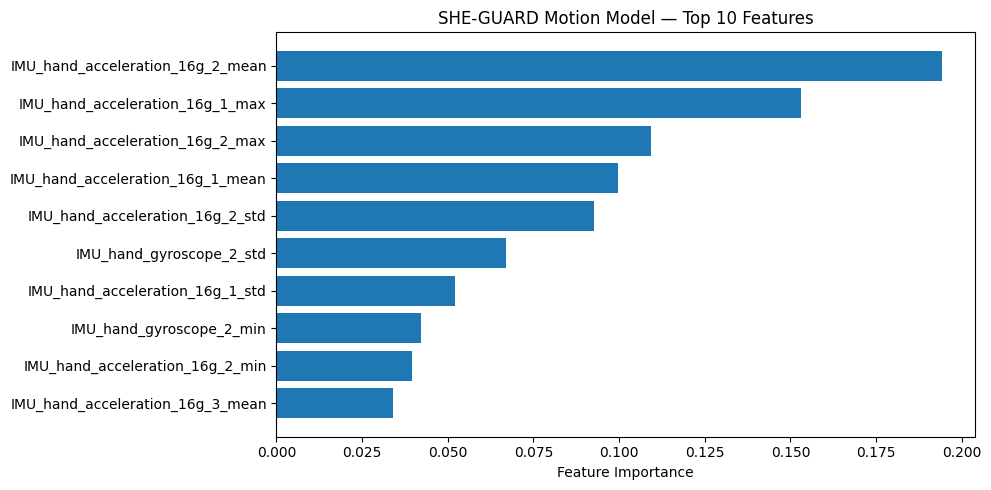

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Feature names in the exact order used during training
feature_names = (
    [f"{c}_mean" for c in wrist_cols] +
    [f"{c}_std" for c in wrist_cols] +
    [f"{c}_min" for c in wrist_cols] +
    [f"{c}_max" for c in wrist_cols]
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": motion_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("Top 10 important features:")
display(importance_df.head(10))

plt.figure(figsize=(10, 5))
top_features = importance_df.head(10).sort_values("Importance")
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("SHE-GUARD Motion Model — Top 10 Features")
plt.tight_layout()
plt.show()

In [ ]:
# Verify feature names and model input dimensions
print("Expected model features:", motion_model.n_features_in_)
print("Feature names count:", len(feature_names))
print("Feature matrix shape:", X_features.shape)

assert motion_model.n_features_in_ == 24
assert len(feature_names) == 24
assert X_features.shape[1] == 24

# Recalculate features from one known test window
sample_window = X_test[0] if False else X_windows[0]

sample_features = np.concatenate([
    np.mean(sample_window, axis=0),
    np.std(sample_window, axis=0),
    np.min(sample_window, axis=0),
    np.max(sample_window, axis=0)
]).reshape(1, -1)

sample_prediction = motion_model.predict(sample_features)[0]
sample_probabilities = motion_model.predict_proba(sample_features)[0]

print("\nFeature order and dimensions: PASS")
print("Sample prediction:", "Running" if sample_prediction == 1 else "Walking")
print(
    "Model confidence:",
    round(float(sample_probabilities.max()) * 100, 2), "%"
)

Expected model features: 24
Feature names count: 24
Feature matrix shape: (521, 24)

Feature order and dimensions: PASS
Sample prediction: Walking
Model confidence: 76.0 %


In [ ]:
# Recreate the 24-feature matrix from the original windows
X_features_check = np.array([
    np.concatenate([
        np.mean(window, axis=0),
        np.std(window, axis=0),
        np.min(window, axis=0),
        np.max(window, axis=0)
    ])
    for window in X_windows
])

# Check that the reconstructed features match the training features
max_difference = np.max(np.abs(X_features_check - X_features))

predictions_original = motion_model.predict(X_features)
predictions_recreated = motion_model.predict(X_features_check)

print("Maximum feature difference:", max_difference)
print(
    "Predictions identical:",
    np.array_equal(predictions_original, predictions_recreated)
)
print("Feature reconstruction check:",
      "PASS" if np.allclose(X_features_check, X_features) else "FAIL")

Maximum feature difference: 0.0
Predictions identical: True
Feature reconstruction check: PASS


In [ ]:
import os
import json
import joblib
import zipfile

from pathlib import Path

# Create a portable integration package
package_dir = Path("/content/SHE_GUARD_Motion_API")
package_dir.mkdir(exist_ok=True)

# Save the already-trained model
joblib.dump(
    motion_model,
    package_dir / "motion_model.pkl"
)

# Save channel order and preprocessing metadata
metadata = {
    "project": "SHE-GUARD",
    "model_type": "RandomForestClassifier",
    "task": "walking_vs_running",
    "sampling_rate_hz": 100,
    "window_samples": 200,
    "window_duration_seconds": 2,
    "channels": wrist_cols,
    "feature_order": ["mean", "std", "min", "max"],
    "features_per_window": 24,
    "labels": {"0": "Walking", "1": "Running"},
    "experimental_mean_held_out_subject_accuracy_percent": 96.09,
    "warning": (
        "Experimental activity classifier, not a distress detector. "
        "Real sensor units and calibration must be validated."
    )
}

(package_dir / "metadata.json").write_text(
    json.dumps(metadata, indent=2)
)

# Inference function: accepts 200 readings with 6 channels
inference_code = r'''
import numpy as np
import joblib
from pathlib import Path

BASE_DIR = Path(__file__).resolve().parent
model = joblib.load(BASE_DIR / "motion_model.pkl")

def predict_motion(readings):
    """
    readings: list of 200 rows, each containing 6 numeric channels.
    Channel order must match metadata.json.
    """
    data = np.asarray(readings, dtype=float)

    if data.shape != (200, 6):
        raise ValueError(
            "Expected exactly 200 readings x 6 channels."
        )

    if not np.isfinite(data).all():
        raise ValueError("Readings contain NaN or infinite values.")

    features = np.concatenate([
        np.mean(data, axis=0),
        np.std(data, axis=0),
        np.min(data, axis=0),
        np.max(data, axis=0)
    ]).reshape(1, -1)

    prediction = int(model.predict(features)[0])
    probabilities = model.predict_proba(features)[0]
    confidence = float(np.max(probabilities))

    return {
        "prediction": "Running" if prediction == 1 else "Walking",
        "class_id": prediction,
        "model_confidence": round(confidence, 4),
        "warning": "Activity estimate only; not an emergency detector."
    }
'''

(package_dir / "predict_motion.py").write_text(inference_code)

# Basic dependency list
(package_dir / "requirements.txt").write_text(
    "numpy\nscikit-learn\njoblib\n"
)

# Zip everything for later integration
zip_path = "/content/SHE_GUARD_Motion_API_Ready.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in package_dir.iterdir():
        z.write(file, arcname=file.name)

print("Package created:", os.path.exists(zip_path))
print("Files:", sorted(p.name for p in package_dir.iterdir()))
print("ZIP size (KB):", round(os.path.getsize(zip_path) / 1024, 2))

Package created: True
Files: ['metadata.json', 'motion_model.pkl', 'predict_motion.py', 'requirements.txt']
ZIP size (KB): 90.04


In [ ]:
from google.colab import files
files.download("/content/SHE_GUARD_Motion_API_Ready.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import zipfile
import os

zip_path = "/content/SHE_GUARD_Motion_API_Ready.zip"
extract_dir = "/content/SHE_GUARD_Motion_API"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Extracted files:")
print(os.listdir(extract_dir))

Extracted files:
['motion_model.pkl', 'metadata.json', 'predict_motion.py', 'requirements.txt']


In [ ]:
import sys
import numpy as np

sys.path.insert(0, "/content/SHE_GUARD_Motion_API")

from predict_motion import predict_motion

# Artificial test data only — not real sensor measurements
rng = np.random.default_rng(42)
fake_readings = rng.normal(
    loc=0.0,
    scale=1.0,
    size=(200, 6)
).tolist()

result = predict_motion(fake_readings)

print("Input shape:", np.asarray(fake_readings).shape)
print("Prediction result:")
print(result)

Input shape: (200, 6)
Prediction result:
{'prediction': 'Walking', 'class_id': 0, 'model_confidence': 0.77, 'warning': 'Activity estimate only; not an emergency detector.'}


In [ ]:
try:
    predict_motion([[0, 0, 0, 0, 0, 0]] * 100)
except ValueError as e:
    print("Invalid input correctly rejected:", e)

Invalid input correctly rejected: Expected exactly 200 readings x 6 channels.


In [ ]:
import joblib
import numpy as np

saved_model = joblib.load(
    "/content/SHE_GUARD_Motion_API/motion_model.pkl"
)

# Recreate the same 24 features from the original windows
X_check = np.array([
    np.concatenate([
        np.mean(window, axis=0),
        np.std(window, axis=0),
        np.min(window, axis=0),
        np.max(window, axis=0)
    ])
    for window in X_windows
])

original_predictions = motion_model.predict(X_check)
saved_predictions = saved_model.predict(X_check)

print("Saved model loaded: True")
print(
    "Predictions identical:",
    np.array_equal(original_predictions, saved_predictions)
)
print(
    "Prediction agreement (%):",
    round(
        np.mean(original_predictions == saved_predictions) * 100,
        2
    )
)

Saved model loaded: True
Predictions identical: True
Prediction agreement (%): 100.0


# ***SHE-GUARD — Complete ML & Alert-System Documentation***


## 1. Project overview

SHE-GUARD is an experimental personal-safety prototype with separate components:

1. Motion ML: classifies wrist-sensor data as Walking or Running.
2. Audio ML: experimental scream/distress-like audio classification.
3. Route-risk component: estimates route/location risk and may recommend an alternative route.
4. Alert workflow: handles warning timers, cancellation, SOS and notifications.
5. Frontend: Emergent web application.
6. Hardware: planned ESP32 + wrist IMU sensor.

**Important:** These are separate components. The current motion model does NOT detect assault, kidnapping, rape or distress. A walking/running prediction is not proof of danger.

---

## 2. Motion ML model: what we trained

### Dataset

We used converted PAMAP2 dataset files for subjects 101, 102 and 105.

The six selected wrist-sensor channels were:

- `IMU_hand_acceleration_16g_1`
- `IMU_hand_acceleration_16g_2`
- `IMU_hand_acceleration_16g_3`
- `IMU_hand_gyroscope_1`
- `IMU_hand_gyroscope_2`
- `IMU_hand_gyroscope_3`

Activity labels:

- `activityID = 4` means Walking
- `activityID = 5` means Running

We removed rows with missing values in these six channels and segmented the data whenever the activity changed or a timestamp gap exceeded 0.02 seconds.

### Cleaned data

| Subject | Walking rows | Running rows | Total rows |
|---|---:|---:|---:|
| 101 | 21,602 | 21,007 | 42,609 |
| 102 | 31,742 | 8,843 | 40,585 |
| 105 | 30,909 | 24,586 | 55,495 |
| **Total** | **84,253** | **54,436** | **138,689** |

### Window creation

We created non-overlapping windows of 200 samples each.

At a nominal sampling rate of 100 Hz:

`200 samples / 100 samples per second = 2 seconds`

Every window contains:

- 200 timestamps
- 6 sensor channels
- One activity label

Total windows: 521

- Walking: 290
- Running: 231
- Subject 101: 169 windows
- Subject 102: 135 windows
- Subject 105: 217 windows

Windows were created within continuous segments so they did not cross an activity change or a timestamp gap.

---

## 3. How raw readings become a prediction

### Step A: Sensor input

The intended input is a 200 x 6 numeric array:

| Column | Channel |
|---|---|
| 1 | Accelerometer X |
| 2 | Accelerometer Y |
| 3 | Accelerometer Z |
| 4 | Gyroscope X |
| 5 | Gyroscope Y |
| 6 | Gyroscope Z |

The actual hardware must use compatible units, axis orientation, calibration and sampling. This has not yet been verified with a real sensor.

### Step B: Validate the input

The inference function checks:

- Exactly 200 rows and 6 channels
- Numeric values
- No NaN or infinite values

Incorrect shape raises:

`Expected exactly 200 readings x 6 channels.`

### Step C: Extract 24 features

For each of the six channels, we calculate:

1. Mean: 6 values
2. Standard deviation: 6 values
3. Minimum: 6 values
4. Maximum: 6 values

Total:

`6 + 6 + 6 + 6 = 24 features`

The feature order must remain identical to training.

### Step D: Random Forest prediction

The model is:

`RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")`

It receives the 24 features and returns:

- `0` = Walking
- `1` = Running

The model confidence comes from `predict_proba()`. It is not a probability that a person is safe, in danger or experiencing an assault.

### Step E: Example output

```json
{
  "prediction": "Walking",
  "class_id": 0,
  "model_confidence": 0.77,
  "warning": "Activity estimate only; not an emergency detector."
}
```

The example confidence is illustrative.

---

## 4. Model evaluation

Each subject was held out once, with the other two subjects used for training.

| Held-out subject | Test windows | Accuracy |
|---|---:|---:|
| 101 | 169 | 94.08% |
| 102 | 135 | 99.26% |
| 105 | 217 | 94.93% |
| **Mean of the three accuracies** | — | **96.09%** |

The 96.09% is an unweighted mean across three subject-wise tests. It is not a guarantee of live sensor accuracy.

Only three subjects were used, so this evaluation is limited. Real ESP32/IMU data may differ from PAMAP2 in units, calibration, placement and axis orientation.

### What does 100% prediction agreement mean?

We loaded the saved model and compared its predictions with the original trained model on the same windows. Prediction agreement was 100%.

This confirms that the saved model reproduces the original model's predictions on those inputs. It does NOT mean the model is 100% accurate in real life.

Random synthetic data is useful only for checking that the software runs. It is not a valid movement-performance test.

---

## 5. Inference package

The package `SHE_GUARD_Motion_API_Ready.zip` contains:

- `motion_model.pkl`: trained Random Forest
- `metadata.json`: channel order, labels, window size and limitations
- `predict_motion.py`: validation, feature extraction and prediction
- `requirements.txt`: Python dependencies

Example Python usage after extracting the ZIP:

```python
from predict_motion import predict_motion

# readings must be 200 real, correctly calibrated rows x 6 channels
result = predict_motion(readings)
print(result)
```

The package has been tested with synthetic input and invalid input. Real sensor validation remains pending.

---

## 6. How will the model connect to the sensor?

Planned architecture:

```text
Wrist IMU sensor
      |
      v
ESP32 reads accelerometer + gyroscope
      |
      v
Collect 200 readings x 6 channels
      |
      v
Wi-Fi sends the window to backend
      |
      v
Backend validates the input
      |
      v
Calculate 24 features
      |
      v
Load/use the trained Random Forest
      |
      v
Return Walking or Running
      |
      v
Emergent dashboard displays the activity estimate
```

The sensor has not yet been purchased or validated in this workflow. The ESP32 and sensor model must be confirmed before exact wiring and sensor code can be finalized.

The backend must use the same feature extraction order as training. It must also check sensor units, axis order and calibration.

---

## 7. Proposed Emergent API contract

A proposed endpoint is:

`POST /api/motion/predict`

This is a design proposal; it does not mean the endpoint has already been deployed.

Example request:

```json
{
  "device_id": "she-guard-001",
  "readings": [
    [0.12, 0.03, 9.71, 0.01, 0.02, 0.03]
  ]
}
```

The real request must contain exactly 200 rows, each with six numeric values. The sample row above is illustrative only.

Example response:

```json
{
  "prediction": "Walking",
  "class_id": 0,
  "model_confidence": 0.77,
  "status": "experimental",
  "warning": "Activity estimate only; not an emergency detector."
}
```

Recommended API behavior:

- 400: malformed request, wrong dimensions, non-numeric values, NaN or infinity
- 503: model unavailable
- Do not expose internal paths, secrets or stack traces
- Load the model once at server startup
- Validate request size
- Add device authorization before accepting real sensor traffic
- Do not treat a client-supplied device ID as authentication
- Avoid unnecessarily storing raw sensor and location data

Before implementation, confirm that the Emergent backend supports Python and scikit-learn. Otherwise, use a compatible Python inference service.

---

## 8. Why might Yelahanka show no alert but MG Road show an alert?

**The exact reason cannot be confirmed without inspecting the actual Emergent route-risk code, data and logs.**

The motion classifier does not know Bengaluru street names. It does not decide that Yelahanka is safe or MG Road is dangerous. Route alerts belong to a separate component.

Possible explanations include:

1. Different calculated risk scores.
2. A configured threshold: alert only if `risk_score >= threshold`.
3. Hard-coded demo or mock data.
4. One coordinate matching a geofence or risk-zone polygon while the other does not.
5. Different API responses for the two locations.
6. Missing or stale risk data for one location.
7. Geocoding resolving a place name to unexpected coordinates.
8. Frontend state, permissions, cooldown or rendering logic suppressing an alert.

These are possibilities, not confirmed causes.

### How to find the actual cause

In the Emergent project, inspect:

- The route-risk calculation function/API
- The risk-data source and record for each location
- The coordinates submitted for Yelahanka and MG Road
- The calculated risk score for each
- The configured alert threshold
- The exact condition that triggers an alert
- API responses and backend/frontend logs
- Any hard-coded sample locations or mock risk values

Useful diagnostic fields:

```text
requested_coordinates
risk_data_source
risk_record_found
risk_score
configured_threshold
alert_decision
decision_reason
```

Possible decision reasons:

- `alert_triggered`
- `below_threshold`
- `risk_data_missing`
- `invalid_coordinates`

The interface should distinguish:

- `ELEVATED_ESTIMATED_RISK`
- `LOWER_ESTIMATED_RISK` when supported by the data
- `UNKNOWN` when reliable data is missing

**No alert does not mean a location is safe.** A risk score is not proof that a street is safe or dangerous.

---

## 9. Keep the components separate

```text
IMU sensor -> ESP32 -> backend -> motion model -> activity estimate

Audio input -> audio model -> audio estimate

Location/route data -> route-risk component -> route advisory

Manual SOS ---------------------------> emergency workflow
```

Important design rules:

- Running alone must not trigger an emergency.
- Walking does not mean the user is safe.
- A missing route alert does not prove safety.
- Manual SOS must work independently of ML.
- If there is a cancellation timer, clearly define how it starts, how cancellation works and what happens without internet.
- Test with designated test contacts before enabling real emergency notifications.

---

## 10. End-to-end validation checklist

### Dataset and ML

- [x] Select walking/running data
- [x] Remove missing selected sensor readings
- [x] Segment at activity changes and timestamp gaps
- [x] Create 200-sample windows
- [x] Extract 24 features
- [x] Evaluate with one held-out subject at a time
- [x] Save model and metadata
- [x] Confirm saved model matches original predictions
- [x] Confirm invalid input dimensions are rejected
- [ ] Validate on real sensor readings
- [ ] Confirm sensor units and axis order
- [ ] Confirm real sampling rate and calibration
- [ ] Evaluate across more people and conditions

### Emergent/backend

- [ ] Confirm Python/scikit-learn support or choose a compatible service
- [ ] Deploy the inference endpoint
- [ ] Test valid request and response
- [ ] Test wrong shape, missing fields, NaN and infinity
- [ ] Add authentication and rate limiting
- [ ] Test disconnect/reconnect and stale readings
- [ ] Show UNKNOWN rather than assuming safety when data is missing

### Route alerts

- [ ] Identify actual risk-data source
- [ ] Confirm coordinates for Yelahanka and MG Road
- [ ] Log risk score for both
- [ ] Identify the threshold and alert rule
- [ ] Test missing and stale data
- [ ] Confirm “no alert” is not displayed as “verified safe”

---

## 11. Cross-questions for a hackathon or viva

### ML and dataset

1. What exact task does the current motion model perform?
2. Why were activity IDs 4 and 5 selected?
3. Why use six wrist-sensor channels?
4. Why are 200 samples approximately two seconds?
5. Why must windows not cross activity boundaries or timestamp gaps?
6. How are the 24 features calculated?
7. Why is feature ordering important?
8. Why hold out a whole subject during evaluation?
9. What does 96.09% mean?
10. Why is evaluation on only three subjects limited?
11. What is the difference between accuracy, precision, recall and model confidence?
12. Why does 100% saved-model agreement not mean 100% real-world accuracy?
13. Why is synthetic input only a software smoke test?
14. What if the real sensor units or axes differ from PAMAP2?
15. What additional data would be required for a different classification task?

### Hardware and backend

16. What does the ESP32 do?
17. What does the IMU measure?
18. Why does the backend need a 200 x 6 window?
19. Why should the model run in a backend instead of trusting the browser?
20. Why validate input shape and numeric values?
21. What should happen if the sensor disconnects?
22. Why is model confidence not a probability of safety?
23. How can the API be tested without sending real emergency alerts?

### Route-risk alerts

24. Does the motion model know location names such as Yelahanka or MG Road?
25. Which separate component calculates route risk?
26. What risk scores and threshold were actually returned for each location?
27. Is the route-risk source live, static, simulated or manually entered?
28. If risk data is missing, should the interface say “safe”?
29. How can geocoding errors affect risk-zone matching?
30. Why must manual SOS work independently of ML?

---

## 12. Final project statement

SHE-GUARD currently includes an experimental wrist-IMU activity classifier trained on PAMAP2 to distinguish walking from running. Its reported unweighted mean accuracy across three held-out-subject evaluations was 96.09%. The saved model reproduced the original model's predictions on the same inputs.

Real-device compatibility, live performance, route-risk data quality and end-to-end emergency workflows remain to be validated. The current motion model is not an assault, kidnapping or distress detector.

---

## 13. Next steps

1. Keep a backup of `SHE_GUARD_Motion_API_Ready.zip`.
2. Inspect Emergent's route-risk code and data before stating why Yelahanka and MG Road behave differently.
3. Implement the proposed inference endpoint.
4. Test using recorded sensor windows.
5. Purchase/confirm the ESP32 and IMU, then validate real readings.
6. Keep manual SOS independent and never treat missing data or a Walking prediction as proof of safety.
